# Introduction to numerical algorithms
## Practice 6: eigenvalues, eigenvectors and finite differences

Topics

- Warmup: spectral operations in `numpy` (det, eigenvalues, eigensystems)
- Task 1: power method
- Task 2: eigenvalue shifts and inverse iteration
- Task 3: coupled oscillators and normal modes
- Task 4: derivatives with central finite differences

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as anim
import scipy.integrate as intgr

np.set_printoptions(precision=5, suppress=True)   # nicer printing of arrays
plt.rcParams["figure.dpi"] = 100
plt.rcParams["animation.html"] = "jshtml"          # animations are shown inline

---
## Warmup

A number $\lambda$ and a non-zero vector $\mathbf{v}$ form an eigenpair of the square matrix $\mathbf{A}$ if
$$\mathbf{A}\mathbf{v}=\lambda\mathbf{v}.$$

Useful functions from `np.linalg`:

| function | what it does |
|---|---|
| `det(A)` | determinant |
| `eigvals(A)` | eigenvalues only |
| `eig(A)` | eigenvalues and eigenvectors of a general matrix, returns `lam, V` |
| `eigh(A)` | the same for symmetric (Hermitian) matrices: faster, real, sorted, orthonormal eigenvectors |

### Warmup 1

$$\mathbf{A}=\begin{pmatrix}2&1\\2&2\end{pmatrix}$$

First find the eigenvalues by hand from $\det(\mathbf{A}-\lambda\mathbf{I})=(2-\lambda)^2-2=0$. Then, with `numpy`:

1. compute `det(A)` and compare it with $ad-bc$,
2. compute the eigenvalues with `np.linalg.eigvals`,
3. compute eigenvalues and eigenvectors with `np.linalg.eig`.

In [5]:
A = np.array([[2., 1.],
              [2., 2.]])

# Work here

det = np.linalg.det(A)
eigenvalues, eigenvectors = np.linalg.eig(A)

`eig` returns the eigenvectors as the **columns** of `V`: the $i$-th eigenvector is `V[:, i]`, not `V[i]`. This is a very common source of bugs.

1. check that $\mathbf{A}\mathbf{v}_i=\lambda_i\mathbf{v}_i$ for both eigenpairs,
2. check that $\operatorname{tr}\mathbf{A}=\sum_i\lambda_i$ and $\det\mathbf{A}=\prod_i\lambda_i$,
3. rebuild the matrix from its eigensystem, $\mathbf{A}=\mathbf{V}\,\mathbf{\Lambda}\,\mathbf{V}^{-1}$ with $\mathbf{\Lambda}=\operatorname{diag}(\lambda_i)$ (`np.diag`).

In [6]:
# Work here

for i in range(len(eigenvalues)):
    if np.allclose(A @ eigenvectors[:, i], eigenvalues[i] * eigenvectors[:, i]):
        print(f"Eigenvalue {eigenvalues[i]} and eigenvector {eigenvectors[:, i]} satisfy the equation.")

if np.isclose(np.trace(A), np.sum(eigenvalues)):
    print(f"Trace of A and sum of eigenvalues are equal: {np.trace(A)} = {np.sum(eigenvalues)}")

if np.isclose(np.linalg.det(A), np.prod(eigenvalues)):
    print(f"Determinant of A and product of eigenvalues are equal: {np.linalg.det(A)} = {np.prod(eigenvalues)}")

A_2 = eigenvectors @ np.diag(eigenvalues) @ np.linalg.inv(eigenvectors)
print(A_2)

Eigenvalue 3.414213562373095 and eigenvector [0.57735 0.8165 ] satisfy the equation.
Eigenvalue 0.5857864376269051 and eigenvector [-0.57735  0.8165 ] satisfy the equation.
Trace of A and sum of eigenvalues are equal: 4.0 = 4.0
Determinant of A and product of eigenvalues are equal: 2.0 = 2.0000000000000004
[[2. 1.]
 [2. 2.]]


### Warmup 2

Consider the matrix
$$\mathbf{A}_4=\begin{pmatrix}2&-1&0&0\\-1&2&-1&0\\0&-1&2&-1\\0&0&-1&2\end{pmatrix}$$
We will use it in Task 1 and Task 2.

1. Compute its eigenvalues with both `eig` and `eigh`. Are they in the same order?
2. For the eigenvectors `V` returned by `eigh`, evaluate `V.T @ V`. What do you see and why?

In [7]:
A4 = np.array([[ 2., -1.,  0.,  0.],
               [-1.,  2., -1.,  0.],
               [ 0., -1.,  2., -1.],
               [ 0.,  0., -1.,  2.]])

# Work here

eig_val, eig_vec = np.linalg.eig(A4)
eigh_val, eigh_vec = np.linalg.eigh(A4)

print(eig_val)
print(eigh_val)

print(np.transpose(eigh_vec) @ eigh_vec)

[3.61803 2.61803 0.38197 1.38197]
[0.38197 1.38197 2.61803 3.61803]
[[ 1.  0. -0. -0.]
 [ 0.  1. -0. -0.]
 [-0. -0.  1. -0.]
 [-0. -0. -0.  1.]]


---
## Task 1: power method

`np.linalg.eig` is a black box. For large matrices we often cannot afford a full decomposition and only want a few eigenvalues. The simplest iterative method is the power method.

Start from a random vector $\mathbf{x}_0$ and repeatedly multiply by $\mathbf{A}$, normalizing each time:
$$\mathbf{x}_{k+1}=\frac{\mathbf{A}\mathbf{x}_k}{\|\mathbf{A}\mathbf{x}_k\|}.$$
Why does it work? Expand $\mathbf{x}_0=\sum_i c_i\mathbf{v}_i$ in eigenvectors. Then
$$\mathbf{A}^k\mathbf{x}_0=\sum_i c_i\lambda_i^k\mathbf{v}_i=\lambda_1^k\Big[c_1\mathbf{v}_1+\sum_{i>1}c_i\Big(\tfrac{\lambda_i}{\lambda_1}\Big)^k\mathbf{v}_i\Big]\;\longrightarrow\;\lambda_1^k c_1\mathbf{v}_1$$
if $|\lambda_1|>|\lambda_2|\ge\dots$. The direction converges to the dominant eigenvector and the error shrinks like $r^k$ with $r=|\lambda_2/\lambda_1|$. The eigenvalue is estimated by the Rayleigh quotient
$$\lambda\approx\frac{\mathbf{x}^T\mathbf{A}\mathbf{x}}{\mathbf{x}^T\mathbf{x}}.$$
Requirements: $\mathbf{x}_0$ must have a component along $\mathbf{v}_1$ (a random vector is fine), the dominant eigenvalue must be unique in magnitude, and convergence is slow if $r\approx1$.

We work with $\mathbf{A}_4$ from Warmup 2 and compare with `eigh`.

Complete `power_method(A, x0=None, tol=1e-10, max_iter=10000)`. It should

- start from a random normalized vector if `x0` is `None`,
- iterate $\mathbf{x}\leftarrow\mathbf{A}\mathbf{x}/\|\mathbf{A}\mathbf{x}\|$,
- estimate $\lambda$ with the Rayleigh quotient in every step,
- stop when two consecutive estimates of $\lambda$ differ by less than `tol` (or after `max_iter` steps),
- return the final `lam` and `x`, the list `lams` of all eigenvalue estimates and the list `xs` of all vectors.

In [ ]:
def power_method(A, x0=None, tol=1e-10, max_iter=10000):
    n = A.shape[0]
    if x0 is None:
        x = np.random.default_rng(0).normal(size=n)
    else:
        x = np.array(x0, dtype=float)
    x = x / np.linalg.norm(x)

    lams, xs = [], [x]
    lam = None
    for k in range(max_iter):
        x_new = A @ x
        x_new = x_new / np.linalg.norm(x_new)
        lam_new = x_new.T @ A @ x_new
        lams.append(lam_new)
        xs.append(x_new)

        if lam is not None and abs(lam_new - lam) < tol:
            x = x_new
            lam = lam_new
            break

        x = x_new
        lam = lam_new

    return lam, x, lams, xs


In [9]:
# Check: compare with eigh
lam_ref, V_ref = np.linalg.eigh(A4)
lam1, v1, lams, xs = power_method(A4)
print(f"power method: lambda_max = {lam1:.10f}   after {len(lams)-1} iterations")
print(f"eigh        : lambda_max = {lam_ref[-1]:.10f}")

power method: lambda_max = 3.6180339887   after 61 iterations
eigh        : lambda_max = 3.6180339887


---
## Task 2: eigenvalue shifts

The matrix $\mathbf{A}-s\mathbf{I}$ has the same eigenvectors as $\mathbf{A}$ and the eigenvalues $\lambda_i-s$. This gives two ways to reach eigenvalues other than the largest.

**Shifted power method.** Apply the power method to $\mathbf{A}-\lambda_1\mathbf{I}$, where $\lambda_1$ is the largest eigenvalue found before. All its eigenvalues are $\le0$, and the one with the largest magnitude belongs to the smallest eigenvalue $\lambda_n$ of $\mathbf{A}$. If the power method returns $\mu$, then $\lambda_n=\mu+\lambda_1$.

Use `lam1` from Task 1 and apply `power_method` to $\mathbf{A}_4-\lambda_1\mathbf{I}$ to get the smallest eigenvalue of $\mathbf{A}_4$. Do not forget to shift back. Compare with `eigh`.

In [12]:
# Use lam1 from the largest-eigenvalue calculation
lam_ref, V_ref = np.linalg.eigh(A4)
lam1, v1, _, _ = power_method(A4)
A_shifted = A4 - lam1 * np.eye(A4.shape[0])
lam_min_shifted, v_min_shifted, lams_shifted, xs_shifted = power_method(A_shifted)
lam_min = lam_min_shifted + lam1

print(f"Shifted power method: {lam_min:.10f}   after {len(lams_shifted)-1} iterations")
print(f"eigh        : lambda_min = {lam_ref[0]:.10f}")


Shifted power method: 6.8541019662   after 9999 iterations
eigh        : lambda_min = 0.3819660113


**Inverse iteration.** Shifting and running the plain power method only ever gives the two extreme eigenvalues of the spectrum. To reach the ones in the middle, apply the power method to the matrix $(\mathbf{A}-s\mathbf{I})^{-1}$. Its eigenvalues are $1/(\lambda_i-s)$, so the dominant one belongs to the eigenvalue of $\mathbf{A}$ closest to the shift $s$. The eigenvectors are the same as those of $\mathbf{A}$.

For simplicity we compute the inverse once with `np.linalg.inv`, before the iteration starts. Each step is then a plain multiplication, exactly as in the power method, but with $(\mathbf{A}-s\mathbf{I})^{-1}$ instead of $\mathbf{A}$. (For large matrices one would not invert explicitly but solve a linear system in every step, see Gauss elimination.)

1. Write `inverse_iteration(A, shift, tol=1e-12, max_iter=1000)` that returns the eigenvalue of $\mathbf{A}$, the eigenvector and the number of iterations. Compute $(\mathbf{A}-s\mathbf{I})^{-1}$ once with `np.linalg.inv`, 
then iterate $\mathbf{x}\leftarrow(\mathbf{A}-s\mathbf{I})^{-1}\mathbf{x}/\|(\mathbf{A}-s\mathbf{I})^{-1}\mathbf{x}\|$. Estimate the eigenvalue with the Rayleigh quotient of the original matrix $\mathbf{A}$, not of the inverted one.
2. Find all four eigenvalues of $\mathbf{A}_4$ using the shifts $s=0.3,\,1.2,\,2.7,\,3.9$ and compare with `eigh`.

In [13]:
def inverse_iteration(A, shift, tol=1e-12, max_iter=1000):
    n = A.shape[0]
    x = np.random.default_rng(1).normal(size=n)
    x = x / np.linalg.norm(x)
    B = np.linalg.inv(A - shift * np.eye(n))
    lam = None
    for k in range(max_iter):
        x = B @ x
        x = x / np.linalg.norm(x)
        lam_new = x.T @ A @ x
        if lam is not None and abs(lam_new - lam) < tol:
            return lam_new, x, k + 1
        lam = lam_new
    return lam, x, max_iter

lam_ref, V_ref = np.linalg.eigh(A4)
for shift in [0.3, 1.2, 2.7, 3.9]:
    lam, x, n_iter = inverse_iteration(A4, shift)
    idx = np.argmin(np.abs(lam_ref - lam))
    print(f"shift = {shift:>3.1f}, eigenvalue ? {lam:.10f}, iterations = {n_iter}, exact = {lam_ref[idx]:.10f}")


shift = 0.3, eigenvalue ? 0.3819660113, iterations = 7, exact = 0.3819660113
shift = 1.2, eigenvalue ? 1.3819660113, iterations = 10, exact = 1.3819660113
shift = 2.7, eigenvalue ? 2.6180339887, iterations = 7, exact = 2.6180339887
shift = 3.9, eigenvalue ? 3.6180339887, iterations = 11, exact = 3.6180339887


---
## Task 3: coupled oscillators

![](osc.png)

Two masses $m_1,m_2$ are connected to each other and to two walls by three springs with spring constants $k_1,k_2,k_3$. Let $x_1,x_2$ be the displacements from equilibrium. Newton's second law gives
$$
m_1\ddot{x}_1=-k_1x_1+k_2(x_2-x_1),\qquad
m_2\ddot{x}_2=-k_3x_2-k_2(x_2-x_1).
$$
(The same follows from the Lagrangian $L=T-V$ with $T=\tfrac12m_1\dot x_1^2+\tfrac12m_2\dot x_2^2$ and $V=\tfrac12k_1x_1^2+\tfrac12k_2(x_2-x_1)^2+\tfrac12k_3x_2^2$.)

In matrix form
$$
\mathbf{M}\ddot{\mathbf{x}}=-\mathbf{K}\mathbf{x},\qquad
\mathbf{M}=\begin{pmatrix}m_1&0\\0&m_2\end{pmatrix},\quad
\mathbf{K}=\begin{pmatrix}k_1+k_2&-k_2\\-k_2&k_2+k_3\end{pmatrix}.
$$
Look for solutions where everything oscillates with the same frequency (a normal mode), $\mathbf{x}(t)=\boldsymbol{\eta}\cos(\omega t+\varphi)$. Substituting gives
$$
\mathbf{K}\boldsymbol{\eta}=\omega^2\mathbf{M}\boldsymbol{\eta}
\quad\Longleftrightarrow\quad
\underbrace{\mathbf{M}^{-1}\mathbf{K}}_{\mathbf{A}}\,\boldsymbol{\eta}=\omega^2\boldsymbol{\eta}.
$$
The mode vectors $\boldsymbol\eta$ are eigenvectors of $\mathbf{A}=\mathbf{M}^{-1}\mathbf{K}$ and the squared frequencies $\omega^2$ are its eigenvalues.

### Brute-force solution (given)
For reference we first integrate the equations numerically with `odeint`. We will learn about numerical integration later.

In [14]:
def equations(state, t, m1, m2, k1, k2, k3):
    """Right-hand side of the equations of motion. state = (x1, x2, v1, v2)."""
    x1, x2, v1, v2 = state
    a1 = (-k1 * x1 + k2 * (x2 - x1)) / m1
    a2 = (-k3 * x2 - k2 * (x2 - x1)) / m2
    return [v1, v2, a1, a2]

def integrate(m1, m2, k1, k2, k3, x0, v0, t):
    """Brute-force numerical solution. Returns X with shape (2, len(t))."""
    sol = intgr.odeint(equations, [*x0, *v0], t, args=(m1, m2, k1, k2, k3))
    return sol[:, :2].T

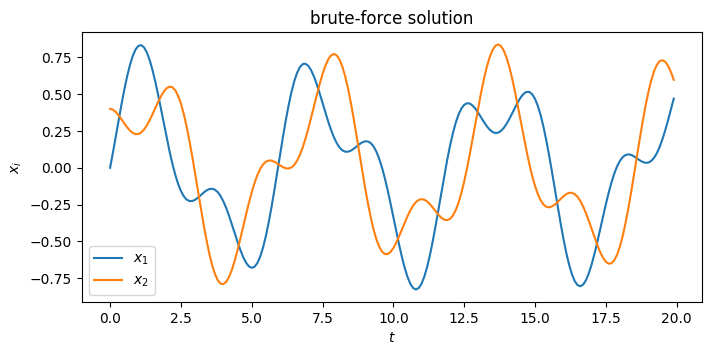

In [15]:
# physical parameters and initial conditions
m1, m2 = 1.0, 1.0
k1, k2, k3 = 1.0, 2.0, 1.0
x0 = np.array([0.0, 0.4])        # initial displacements
v0 = np.array([1.0, 0.0])        # initial velocities

t = np.arange(0, 20, 0.1)        # time points
X_num = integrate(m1, m2, k1, k2, k3, x0, v0, t)

plt.figure(figsize=(8, 3.5))
for i in range(2):
    plt.plot(t, X_num[i], label=f'$x_{i+1}$')
plt.xlabel('$t$'); plt.ylabel('$x_i$'); plt.legend(); plt.title('brute-force solution')
plt.show()

The motion looks irregular. We want to understand it as a superposition of two simple, perfectly periodic normal modes.

### Eigenproblem
1. Build $\mathbf{M}$ and $\mathbf{K}$ as `numpy` arrays and compute $\mathbf{A}=\mathbf{M}^{-1}\mathbf{K}$.
2. Compute its eigenvalues `lam` and eigenvectors `R` with `np.linalg.eig`. Sort them so that the eigenvalues are ascending (hint: `np.argsort`, and reorder the columns of `R` accordingly).
3. Compute the normal frequencies $\omega_i=\sqrt{\lambda_i}$.
4. Look at the mode vectors. What does each mode look like physically (do the masses move in the same or in opposite directions)?

In [16]:
# Work here
M  = np.diag([m1, m2])
K = np.array([[k1 + k2, -k2],
              [-k2, k2 + k3]])
A = np.linalg.inv(M) @ K

lam, R = np.linalg.eigh(A)
# sort
lam, R = np.sort(lam), R[:, np.argsort(lam)]
omega = np.sqrt(lam)

print("omega =", omega)
print("mode vectors (columns):\n", R)

omega = [1.      2.23607]
mode vectors (columns):
 [[-0.70711 -0.70711]
 [-0.70711  0.70711]]


### Solution in terms of modes
Write $\mathbf{A}=\mathbf{R}\boldsymbol{\Lambda}\mathbf{R}^{-1}$ and introduce the normal coordinates $\mathbf{q}=\mathbf{R}^{-1}\mathbf{x}$. The equations decouple:
$$
\ddot{\mathbf{q}}=-\boldsymbol\Lambda\mathbf{q}\quad\Longrightarrow\quad \ddot q_i=-\omega_i^2q_i
\quad\Longrightarrow\quad q_i(t)=c_i\cos(\omega_it)+s_i\sin(\omega_it),
$$
with the amplitudes fixed by the initial conditions,
$$
\mathbf{c}=\mathbf{R}^{-1}\mathbf{x}(0),\qquad
\mathbf{s}=\frac{\mathbf{R}^{-1}\dot{\mathbf{x}}(0)}{\boldsymbol\omega}\quad\text{(component-wise division)}.
$$
Transforming back gives $\mathbf{x}(t)=\mathbf{R}\,\mathbf{q}(t)=\sum_i\boldsymbol\eta_i\,q_i(t)$.

Write `modal_solution(R, omega, x0, v0, t)` which returns the normal coordinates `q` (shape `(2, len(t))`) and the displacements `X` (shape `(2, len(t))`). Then compare with the brute-force result. Avoid loops over time (`omega[:, None] * t` has shape `(2, len(t))`).

In [18]:
def modal_solution(R, omega, x0, v0, t):
    # Work here
    # 1. amplitudes c and s from the initial conditions
    c = np.linalg.inv(R) @ x0
    s = np.linalg.inv(R) @ (v0 / omega)
    # 2. q_i(t) = c_i cos(omega_i t) + s_i sin(omega_i t)
    q = np.array([c[i] * np.cos(omega[i] * t) + s[i] * np.sin(omega[i] * t) for i in range(len(omega))])
    # 3. X = R q
    X = R @ q
    return q, X

q, X_modes = modal_solution(R, omega, x0, v0, t)

# Check: the difference should be tiny (1e-6 or smaller, odeint has its own tolerance)
print("max |brute force - modes| =", np.max(np.abs(X_num - X_modes)))

max |brute force - modes| = 0.27638895821521636


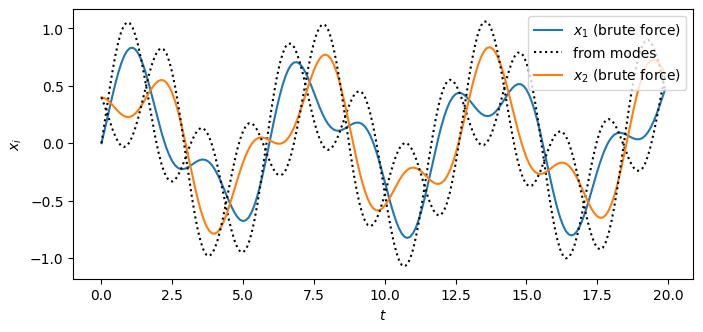

In [19]:
plt.figure(figsize=(8, 3.5))
for i in range(2):
    plt.plot(t, X_num[i], label=f'$x_{i+1}$ (brute force)')
    plt.plot(t, X_modes[i], 'k:', label='from modes' if i == 0 else None)
plt.xlabel('$t$'); plt.ylabel('$x_i$'); plt.legend(); plt.show()

### Visualizing the modes
Make two side-by-side plots (`plt.subplots(1, 2)`), one per mode. In plot $n$ show the contribution of mode $n$ to the two masses, $x_i^{(n)}(t)=R_{in}\,q_n(t)$ for $i=1,2$. Put the frequency $\omega_n$ into the title.

Is each individual curve perfectly periodic? What do the two masses do relative to each other within one mode?

<>:10: SyntaxWarning: invalid escape sequence '\o'
<>:10: SyntaxWarning: invalid escape sequence '\o'
C:\Users\Feri\AppData\Local\Temp\ipykernel_3916\2021741486.py:10: SyntaxWarning: invalid escape sequence '\o'
  omega_str = ", ".join([f'$\omega_{i+1} = {omega[i]:.3f}$' for i in range(len(omega))])


<Figure size 800x350 with 0 Axes>

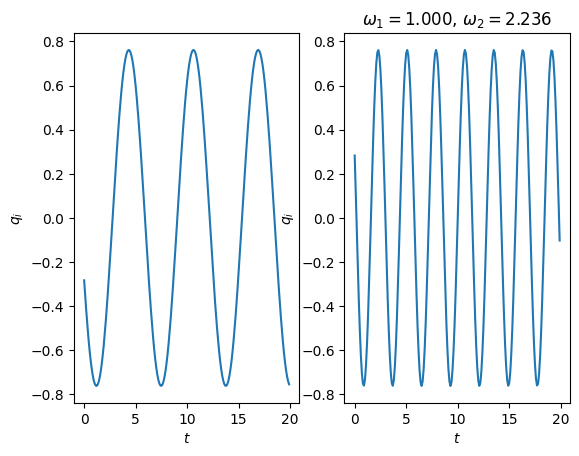

In [28]:
# Work here
plt.figure(figsize=(8, 3.5))
plt.subplots(1,2)
for i in range(2):
    plt.subplot(1, 2, i+1)
    plt.plot(t, q[i], label=f'$q_{i+1}$')
    plt.xlabel('$t$')
    plt.ylabel('$q_i$')

omega_str = ", ".join([f'$\omega_{i+1} = {omega[i]:.3f}$' for i in range(len(omega))])
plt.title(omega_str)

plt.show()


### Animation (given)
The first animation shows the masses: the bottom row is the real motion, the other two rows show each mode separately. The second animation shows the trajectory in the $(x_1,x_2)$ plane. The straight lines are the mode directions (eigenvectors), and the real motion is the sum of two simple oscillations along these lines.

In [29]:
def animate_modes(R, q, X_modes, t):
    """Masses on a line: total motion (bottom row) and the individual modes."""
    fig, ax = plt.subplots(figsize=(5, 3.2), dpi=70)
    ax.set_xlim(-0.4, 3.4); ax.set_ylim(-0.6, 3.3); ax.axis('off')
    rows = [0.0, 1.3, 2.6]
    for y, lab in zip(rows, ['all modes', 'mode 1', 'mode 2']):
        ax.text(-0.4, y + 0.3, lab)
        for xw in (0, 3):
            ax.plot([xw, xw], [y - 0.15, y + 0.15], 'k', lw=3)
    lines = [ax.plot([], [], '-', color='gray', lw=1.5)[0] for _ in rows]
    dots = [ax.plot([], [], 'o', ms=14, color=c)[0] for c in ('C2', 'C0', 'C1')]

    def frame(i):
        displ = [X_modes[:, i], R[:, 0] * q[0, i], R[:, 1] * q[1, i]]
        for y, d, ln, dt in zip(rows, displ, lines, dots):
            xs = np.array([0.0, 1 + d[0], 2 + d[1], 3.0])      # wall, mass 1, mass 2, wall
            ln.set_data(xs, [y] * 4)
            dt.set_data(xs[1:3], [y] * 2)

    mov = anim.FuncAnimation(fig, frame, frames=range(0, len(t), 2), interval=100)   # every 2nd time step
    plt.close(fig)
    return mov

mov = animate_modes(R, q, X_modes, t)
mov

In [30]:
def animate_config_space(R, q, X_modes, t):
    """Trajectory in the (x1, x2) plane together with the two eigen-directions."""
    fig, ax = plt.subplots(figsize=(4, 4), dpi=70)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect('equal')
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.plot(*np.array([R[:, 0], -R[:, 0]]).T, color='C0', lw=1)   # direction of mode 1
    ax.plot(*np.array([R[:, 1], -R[:, 1]]).T, color='C1', lw=1)   # direction of mode 2
    p1, = ax.plot([], [], 'o', color='C0', label='mode 1')
    p2, = ax.plot([], [], 'o', color='C1', label='mode 2')
    p0, = ax.plot([], [], '-', color='C2', label='total motion')
    ax.legend(loc='upper left')

    def frame(i):
        p1.set_data([R[0, 0] * q[0, i]], [R[1, 0] * q[0, i]])
        p2.set_data([R[0, 1] * q[1, i]], [R[1, 1] * q[1, i]])
        p0.set_data(X_modes[0, :i + 1], X_modes[1, :i + 1])

    mov = anim.FuncAnimation(fig, frame, frames=range(0, len(t), 2), interval=100)   # every 2nd time step
    plt.close(fig)
    return mov

mov2 = animate_config_space(R, q, X_modes, t)
mov2

In [ ]:
# optional: save as GIFs
# from matplotlib.animation import PillowWriter
# mov.save('modes.gif',  writer=PillowWriter(fps=20))
# mov2.save('config_space.gif', writer=PillowWriter(fps=20))

---
## Task 4: derivatives with central finite differences

If we only know the values $y_i=f(x_i)$ on an equidistant grid $x_i=a+ih$, we can estimate the derivative from Taylor expansions around $x_i$:
$$f(x+h)=f+hf'+\tfrac{h^2}{2}f''+\tfrac{h^3}{6}f^{(3)}+\dots,\qquad f(x-h)=f-hf'+\tfrac{h^2}{2}f''-\tfrac{h^3}{6}f^{(3)}+\dots$$
Subtracting the two, the even terms cancel and we get the central difference
$$f'(x_i)\approx\frac{y_{i+1}-y_{i-1}}{2h},\qquad\text{error }O(h^2).$$
Using two neighbours on each side we can also cancel the $h^3$ term, which gives a fourth order formula
$$f'(x_i)\approx\frac{y_{i-2}-8y_{i-1}+8y_{i+1}-y_{i+2}}{12h},\qquad\text{error }O(h^4).$$

Write a function `my_der_calc(f, a, b, N, order)` where

- `f` is a function that accepts arrays, `a < b` are the interval ends, `N >= 10` is the number of grid points,
- `order` is 2 or 4 and selects the formula above,
- the grid is `x = np.linspace(a, b, N)`, `y = f(x)`, `h = x[1] - x[0]`,
- the output is `[df, X]`: the derivative and the grid points `X` where it is defined.

Near the ends of the interval the formula would need points outside the grid, so these points are lost: one point at each end for order 2, two points at each end for order 4. Use array slicing instead of loops (for order 2, `y[2:]` are the $y_{i+1}$ and `y[:-2]` are the $y_{i-1}$ for $i=1,\dots,N-2$).

In [32]:
def my_der_calc(f, a, b, N, order=2):
    """
    First derivative of f on [a, b] with N equidistant points, central differences.
    order : 2 or 4 (order of the error O(h^order))
    Returns [df, X]: derivative values and the grid points where they are defined.
    """
    # input checks (given)
    if not callable(f):
        raise TypeError("f must be callable")
    a, b, N = float(a), float(b), int(N)
    if not a < b:
        raise ValueError("a must be smaller than b")
    if N < 10:
        raise ValueError("N must be at least 10")
    if order not in (2, 4):
        raise ValueError("order must be 2 or 4")

    x = np.linspace(a, b, N)
    y = f(x)
    h = x[1] - x[0]

    # Work here
    if order == 2:
        df = (y[2:] - y[:-2]) / (2 * h)
        X = x[1:-1]
    else:
        df = (y[4:] - 4*y[3:-1] + 4*y[1:-3] - y[:-4]) / (2 * h**2)
        X = x[2:-2]
    return [df, X]

### Testing

Compare with the analytic derivative (given). First $\sin x$ on a coarse grid, then a function that oscillates faster and faster and therefore needs a finer grid.

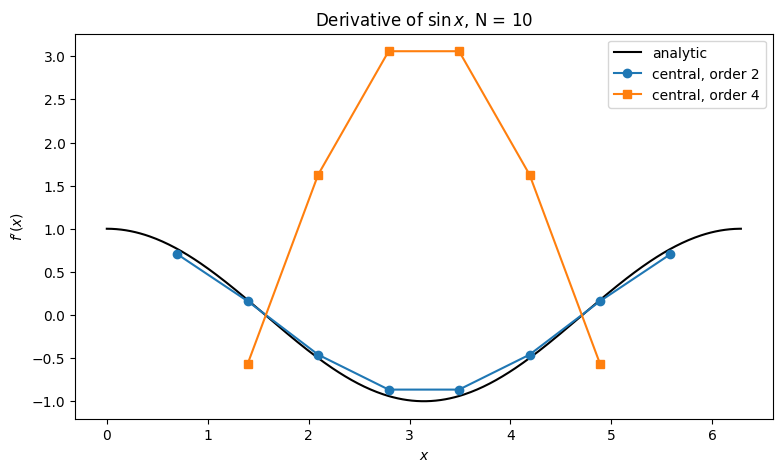

In [33]:
# Test 1: sin(x) on a coarse grid
xx = np.linspace(0, 2*np.pi, 400)
dy2, X2 = my_der_calc(np.sin, 0., 2*np.pi, 10, 2)
dy4, X4 = my_der_calc(np.sin, 0., 2*np.pi, 10, 4)

plt.figure(figsize=(9, 5))
plt.plot(xx, np.cos(xx), 'k', label='analytic')
plt.plot(X2, dy2, 'o-', label='central, order 2')
plt.plot(X4, dy4, 's-', label='central, order 4')
plt.legend(); plt.xlabel('$x$'); plt.ylabel("$f'(x)$"); plt.title(r"Derivative of $\sin x$, N = 10")
plt.show()

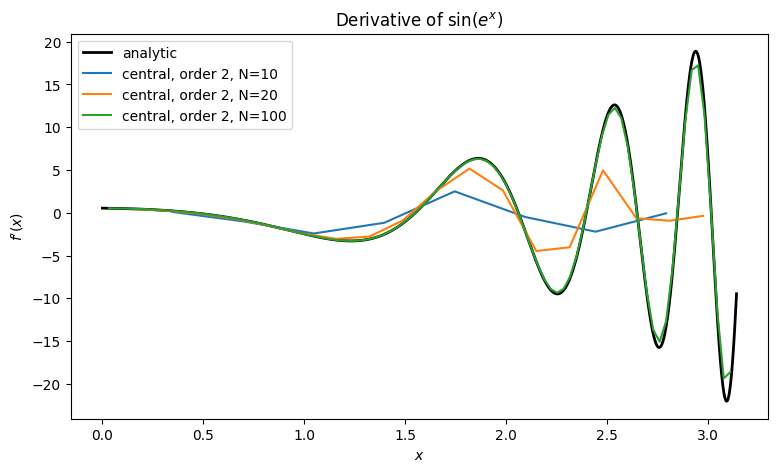

In [34]:
# Test 2: sin(exp(x))
f = lambda x: np.sin(np.exp(x))
df_exact = lambda x: np.cos(np.exp(x)) * np.exp(x)
xx = np.linspace(0, np.pi, 2000)

plt.figure(figsize=(9, 5))
plt.plot(xx, df_exact(xx), 'k', lw=2, label='analytic')
for N in (10, 20, 100):
    dy, X = my_der_calc(f, 0., np.pi, N, 2)
    plt.plot(X, dy, label=f'central, order 2, N={N}')
plt.legend(); plt.xlabel('$x$'); plt.ylabel("$f'(x)$"); plt.title(r"Derivative of $\sin(e^x)$")
plt.show()

### Convergence and round-off error
How does the error depend on the step size $h$? The truncation error is $E\approx Ch^p$, so on a log-log plot we expect a straight line with slope $p$.

1. For $f(x)=\sin x$ on $[0,\pi]$ compute the maximum absolute error
$$E=\max_i\,\big|\cos(X_i)-df_i\big|$$
for both orders (2 and 4) and for many grids, `Ns = np.unique(np.logspace(1, 6.5, 30).astype(int))` (from 10 to about $3\cdot10^6$ points).
2. Plot $E$ against $h=(b-a)/(N-1)$ on a log-log scale (`plt.loglog`), with dashed reference lines $h^2$ and $h^4$.
3. Do the curves have the expected slopes? What happens for very small $h$? Why? Think about what happens when you subtract two almost identical floating point numbers and divide by a tiny $h$.
4. Optional: estimate the experimental order of convergence from consecutive points,
$$p\approx\frac{\log(E_i/E_{i+1})}{\log(h_i/h_{i+1})}.$$

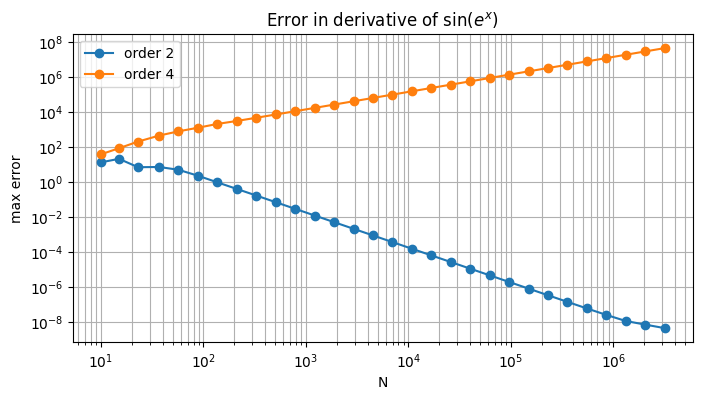

In [35]:
a, b = 0., np.pi
Ns = np.unique(np.logspace(1, 6.5, 30).astype(int))
orders = [2, 4]

# Work here
errors = np.zeros((len(orders), len(Ns)))
for i, order in enumerate(orders):
    for j, N in enumerate(Ns):
        dy, X = my_der_calc(f, a, b, N, order)
        errors[i, j] = np.max(np.abs(dy - df_exact(X)))

plt.figure(figsize=(8, 4))
for i, order in enumerate(orders):
    plt.loglog(Ns, errors[i], 'o-', label=f'order {order}')
plt.xlabel('N'); plt.ylabel('max error'); plt.title(r"Error in derivative of $\sin(e^x)$")
plt.legend(); plt.grid(which='both'); plt.show()
